# 04 · Colonies de fourmis (MAX-MIN Ant System)

Théorie complète : `docs/theory/01_ant_colony.md`. Code : `optimizer/algorithms/ant_colony.py`.

**Construction d'une fourmi.** Les qubits logiques sont placés dans un ordre fixe $i_1, \dots, i_n$. À l'étape $t$, la fourmi choisit un qubit physique libre $u \in J_t$ avec la probabilité (formule 4.1 du cours)

$$
p_{i_t u} = \frac{\tau_{i_t u}^{\,\alpha}\;\eta_{i_t u}^{\,\beta}}{\sum_{v \in J_t} \tau_{i_t v}^{\,\alpha}\;\eta_{i_t v}^{\,\beta}}, \qquad
\eta_{i_t u} = \frac{1}{1 + g_t(u)}, \qquad
g_t(u) = \sum_{j \in L_t} w_{i_t j}\,\big(d(u, s(j)) - 1\big)
$$

où $L_t$ est l'ensemble des qubits déjà placés.
- $\tau \in \mathbb{R}^{n \times m}$ : phéromones, la mémoire apprise à partir de $f$.
- $g_t(u)$ : coût de distance **ajouté** si $i_t$ est placé sur $u$.
- Premier qubit : $\eta = \deg_C(u) / \max \deg_C$ (centralité).

**Propriété.** Chaque arête de $G_I$ est comptée une seule fois, au placement de la seconde extrémité, d'où $\sum_t g_t(s(i_t)) = C(s)$. L'heuristique est donc un glouton sur $C$ ; seule $\tau$ apporte l'information de $f$.

**Une itération.**
1. Construire $N$ fourmis, les trier par $C$ et n'évaluer avec $f$ que les $N_e$ meilleures.
2. Mettre à jour les phéromones. Ici $s^{\mathrm{it}}$ est la meilleure fourmi de l'itération, $s^{\mathrm{bs}}$ la meilleure depuis le début et $e$ le poids élitiste (`elite_weight`) :

$$
\tau \leftarrow (1 - \rho)\,\tau, \qquad
\tau_{i\,s^{\mathrm{it}}(i)} \mathrel{+}= \frac{f(s^{\mathrm{bs}})}{f(s^{\mathrm{it}})}, \qquad
\tau_{i\,s^{\mathrm{bs}}(i)} \mathrel{+}= e, \qquad
\tau \leftarrow \mathrm{clip}\big(\tau, \tau_{\min}, \tau_{\max}\big)
$$

Avec $\tau_{\max} = 1/\rho$ (point fixe d'un dépôt de 1 par itération), $\tau_{\min} = r\,\tau_{\max}$ et $\tau = \tau_{\max}$ au départ. Le budget donne $T = \lceil B / N_e \rceil$ itérations.

| Symbole | Code | `BASE` | Rôle |
|---|---|---|---|
| $N$ | `ants` | 30 | fourmis construites par itération |
| $N_e$ | `evaluated` | 5 | fourmis évaluées avec $f$, d'où $T = 40$ |
| $\alpha$, $\beta$ | `alpha`, `beta` | 1, 2 | poids de la mémoire et de l'heuristique |
| $\rho$ | `rho` | 0,2 | évaporation ; demi-vie d'un dépôt $\ln 2 / (-\ln(1-\rho)) \approx 3$ itérations |
| $r$ | `tau_min_ratio` | 0,05 | $\tau_{\max} / \tau_{\min} = 20$ |
| $e$ | `elite_weight` | 1 | dépôt de $s^{\mathrm{bs}}$ |

In [1]:
import math
import os
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator  # graduations entières sur les axes
from scipy import stats  # test statistique de Mann-Whitney

from goc import hardware
from goc.paths import RESULTS_ROOT, SOLUTIONS_ROOT
# Socle d'optimisation : instances, vraie fitness, coût de distance, lancement et sauvegarde des exécutions.
from optimizer import Problem, available_instances, distance_cost, history_frame, load_instance, load_results, results_frame, run_grid, save_results, write_solution_if_better
# Algorithmes : la colonie de fourmis et trois références.
from optimizer.algorithms import ant_colony, identity, random_search, surrogate_filtered

In [2]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

## Paramètres

`INSTANCE_ID` est l'instance des sections 1 et 2. Les exécutions sont enregistrées dans `results/ant_colony/` ; `RECOMPUTE = True` les refait (environ 30 minutes).

In [3]:
# Instance utilisée pour les explications détaillées (sections 1 et 2).
INSTANCE_ID = 6
# Graine de l'exécution détaillée.
SEED = 0
# Nombre de vraies évaluations par exécution (identique pour tous les algorithmes).
BUDGET = 200
# Graines utilisées pour la comparaison finale (une exécution par graine).
SEEDS = [0, 1, 2, 3, 4]
# Instances de la comparaison finale : toutes celles disponibles.
COMPARISON_INSTANCES = available_instances()
# Instances et graines des études de paramètres (3 : coût de distance peu fiable, 9 : très fiable).
STUDY_INSTANCES = [3, 9]
STUDY_SEEDS = [0, 1, 2]
# Nombre de réévaluations des meilleures solutions (section 5).
REEVALUATIONS = 10
# Nombre de processus en parallèle (nombre de cœurs moins 4, pour garder la machine utilisable).
WORKERS = max(1, (os.cpu_count() or 2) - 4)
# False : relire les exécutions enregistrées ; True : tout recalculer (≈ 30 minutes).
RECOMPUTE = False
# Dossier où les exécutions sont enregistrées.
CACHE_DIR = RESULTS_ROOT / "ant_colony"
# Nom du groupe pour les fichiers solutions, et dossier où ils sont écrits.
GROUP = "Groupe0"
SOLUTIONS_DIR = SOLUTIONS_ROOT

# Réglage de référence de la colonie (voir optimizer/algorithms/ant_colony.py pour le sens de chaque paramètre).
BASE = {
    "ants": 30,  # fourmis construites par itération
    "evaluated": 5,  # fourmis vraiment évaluées par itération (les 5 meilleures selon le coût de distance)
    "alpha": 1.0,  # poids des phéromones
    "beta": 2.0,  # poids de l'heuristique
    "rho": 0.2,  # évaporation
    "tau_min_ratio": 0.05,  # tau_min = 5 % de tau_max
    "elite_weight": 1.0,  # dépôt de la meilleure solution globale
    "local_search_steps": 0,  # pas de recherche locale
}
# Pour les études et la comparaison, on ne garde pas les copies de la matrice des phéromones (fichiers plus légers).
NO_SNAPSHOTS = {"snapshot_every": 10**6}

In [4]:
def cached_grid(name, algorithms, instance_ids, seeds, budget):
    """Lance run_grid, ou relit le résultat déjà enregistré dans CACHE_DIR/<name>.jsonl."""
    path = CACHE_DIR / f"{name}.jsonl"
    if path.exists() and not RECOMPUTE:
        results = load_results(path)
        print(f"Loaded {len(results)} runs from {path}")
        return results
    results = run_grid(algorithms, instance_ids, seeds, budget, workers=WORKERS)
    save_results(results, path)
    return results


def iterations_frame(result):
    """Tableau des indicateurs enregistrés par la colonie à chaque itération."""
    return pd.DataFrame(result.trace["iterations"])


def distance_color(distance):
    """Couleur associée à une distance sur la puce (3 et plus partagent la même couleur rouge)."""
    return DISTANCE_COLORS[min(int(distance), 3)]


def display_table(frame, value="best_cost"):
    """Tableau lisible : pour chaque algorithme et instance, « moyenne ± écart-type (meilleur) »."""
    cells = frame.groupby(["algorithm", "instance_id"], sort=False)[value].agg(lambda s: f"{s.mean():.1f} ± {s.std(ddof=0):.1f} ({s.min():g})")
    return cells.unstack("instance_id").rename(columns=lambda c: f"inst. {c}")

## 1. Construction d'une fourmi

Phéromones uniformes ($\tau = \tau_{\max}$, première itération) : $\tau^\alpha$ se simplifie dans $p$, et seule l'heuristique guide les choix.

**Ordre de construction :**

$$
i_1 = \arg\max_i \mathrm{str}(i), \qquad i_t = \arg\max_{i \notin L_t} \Big(\textstyle\sum_{j \in L_t} w_{ij},\ \mathrm{str}(i),\ -i\Big)
$$

Chaque qubit est placé quand il a le plus de partenaires déjà posés, de sorte que $g_t$ soit informatif. Le tableau vérifie aussi numériquement que $\sum_t g_t(s(i_t)) = C(s)$.

In [5]:
instance = load_instance(INSTANCE_ID)
coordinates = np.array(hardware.coordinates(instance.m, instance.edges), dtype=float)
# Colonie avec les réglages de référence (ordre de placement et heuristique).
colony = ant_colony.Colony(instance, BASE["alpha"], BASE["beta"])
tau_min, tau_max = ant_colony.pheromone_bounds(BASE["rho"], BASE["tau_min_ratio"])
# Phéromones uniformes (toutes au maximum), comme au début d'une exécution.
uniform = np.full((instance.n, instance.m), tau_max)
# Construction d'une fourmi en gardant le détail de chaque étape (record=True).
demo_mapping, demo_steps = colony.construct(uniform, np.random.default_rng(SEED), record=True)

# Tableau de l'ordre de placement : pour chaque étape, le qubit placé et ses liens avec les qubits déjà placés.
order_table = pd.DataFrame({
    "step": range(1, instance.n + 1),
    "logical qubit": [f"q{q}" for q in colony.order],
    "gates with already placed qubits": [int(colony.weights[q, colony.order[:k]].sum()) for k, q in enumerate(colony.order)],
    "total 2-qubit gates": [int(colony.weights[q].sum()) for q in colony.order],
    "chosen physical qubit": [f"P{demo_mapping[q]}" for q in colony.order],
})
# g_t : coût ajouté par le choix fait à l'étape t (portes avec les qubits déjà placés × (distance − 1)).
added = []
for k, q in enumerate(colony.order):
    added.append(int(sum(colony.weights[q, j] * (instance.distances[demo_mapping[q], demo_mapping[j]] - 1) for j in colony.order[:k])))
order_table["g_t(s(i_t))"] = added
print(f"sum of g_t = {sum(added)} ; C(s) of this ant = {distance_cost(instance, demo_mapping)}")
order_table

sum of g_t = 48 ; C(s) of this ant = 48


,step,logical qubit,gates with already placed qubits,total 2-qubit gates,chosen physical qubit,g_t(s(i_t))
0,1,q0,0,4,P12,0
1,2,q10,2,4,P7,0
2,3,q11,2,4,P4,6
3,4,q3,2,4,P1,4
4,5,q2,2,4,P6,0
5,6,q13,4,4,P14,10
6,7,q1,0,4,P13,0
7,8,q9,2,4,P18,0
8,9,q8,2,4,P17,0
9,10,q12,4,4,P19,4


**Probabilités pas à pas.** Chaque panneau représente une étape $t$ : la couleur et la valeur sur chaque qubit libre donnent $p_{i_t u}$, et le cercle noir marque le qubit tiré. À la première étape, $p \propto \mathrm{centralité}^\beta$ ; ensuite, la masse se concentre sur les $u$ tels que $g_t(u) = 0$, voisins des partenaires déjà placés.

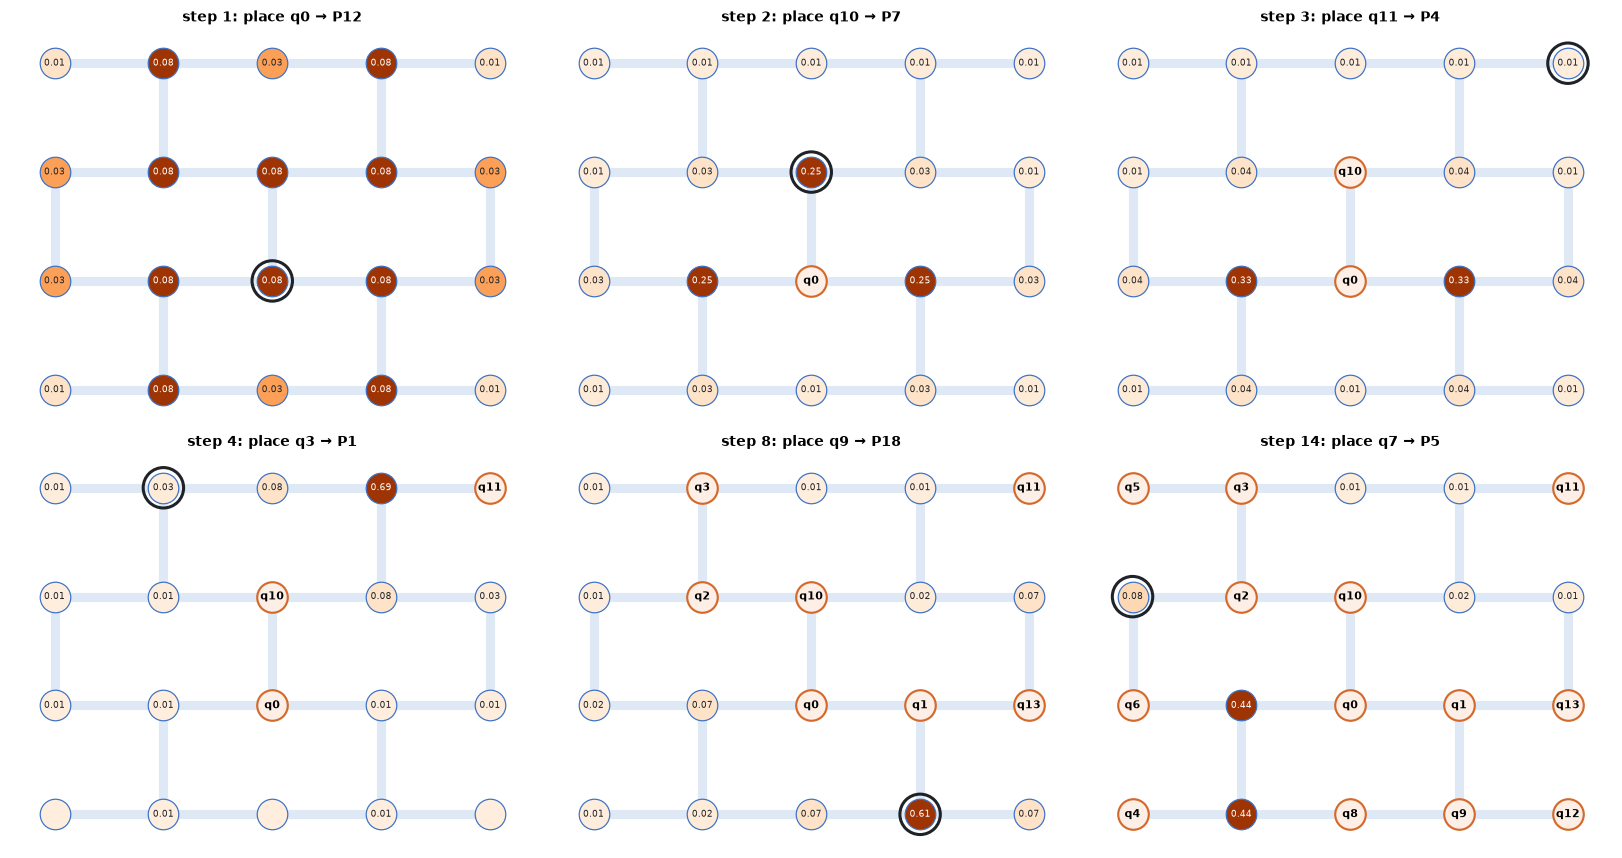

In [6]:
def curve_points(start, end, bend):
    """Points d'une courbe (Bézier quadratique) entre deux positions, décalée de `bend` sur le côté."""
    start, end = np.asarray(start), np.asarray(end)
    direction = end - start
    normal = np.array([-direction[1], direction[0]]) / (np.linalg.norm(direction) or 1)
    control = (start + end) / 2 + normal * bend
    t = np.linspace(0, 1, 30)[:, None]
    return (1 - t) ** 2 * start + 2 * (1 - t) * t * control + t ** 2 * end


def draw_chip(ax, instance, coordinates, mapping=None, values=None, chosen=None, show_interactions=False, title=""):
    """Dessine la puce sur l'axe `ax`.

    - mapping : placement à afficher (les valeurs -1 = qubits pas encore placés) ;
    - values : une valeur par qubit physique libre (par ex. une probabilité), affichée en couleur ;
    - chosen : qubit physique entouré en noir ;
    - show_interactions : superpose les interactions du circuit, colorées selon la distance.
    """
    # Connexions physiques de la puce.
    for a, b in instance.edges:
        ax.plot(*coordinates[[a, b]].T, color=PHYSICAL_SOFT, linewidth=6, solid_capstyle="round", zorder=1)
    # Qubit physique -> qubit logique qui l'occupe (seulement les qubits déjà placés).
    owner = {} if mapping is None else {int(p): q for q, p in enumerate(mapping) if p >= 0}
    if show_interactions and mapping is not None:
        max_weight = max(int(instance.weights.max()), 1)
        for index, ((a, b), weight) in enumerate(zip(instance.pairs, instance.weights)):
            pa, pb = mapping[a], mapping[b]
            distance = instance.distances[pa, pb]
            width = 0.8 + 2 * math.sqrt(weight / max_weight)
            if distance == 1:
                ax.plot(*coordinates[[pa, pb]].T, color=distance_color(1), linewidth=width, zorder=2)
            else:
                # Courbe pour ne pas passer sur les qubits intermédiaires.
                bend = (0.3 if index % 2 else -0.3) * min(np.linalg.norm(coordinates[pb] - coordinates[pa]), 3)
                points = curve_points(coordinates[pa], coordinates[pb], bend)
                ax.plot(points[:, 0], points[:, 1], color=distance_color(distance), linewidth=width, linestyle=(0, (3, 2)), zorder=2)
    cmap = plt.get_cmap("Oranges")
    # Valeur maximale, pour normaliser les couleurs.
    top = values.max() if values is not None and values.max() > 0 else 1.0
    for p, (x, y) in enumerate(coordinates):
        if p in owner:
            # Qubit occupé : disque orange clair avec le qubit logique.
            ax.scatter(x, y, s=400, color=LOGICAL_SOFT, edgecolors=LOGICAL, linewidths=1.4, zorder=3)
            ax.text(x, y, f"q{owner[p]}", ha="center", va="center", fontsize=7, fontweight="bold", zorder=4)
        elif values is not None:
            # Qubit libre coloré selon sa valeur (probabilité), valeur écrite si elle n'est pas négligeable.
            ax.scatter(x, y, s=400, color=cmap(0.05 + 0.85 * values[p] / top), edgecolors=PHYSICAL, linewidths=0.8, zorder=3)
            ax.text(x, y, f"{values[p]:.2f}" if values[p] >= 0.005 else "", ha="center", va="center", fontsize=6, color="white" if values[p] > 0.6 * top else "#1f2328", zorder=4)
        else:
            # Qubit libre sans valeur : cercle blanc en pointillés avec son numéro.
            ax.scatter(x, y, s=260, color="white", edgecolors=PHYSICAL, linewidths=1, linestyle="--", zorder=3)
            ax.text(x, y, str(p), ha="center", va="center", fontsize=6, color=PHYSICAL, zorder=4)
        if chosen == p:
            ax.scatter(x, y, s=700, facecolors="none", edgecolors="#1f2328", linewidths=2, zorder=5)
    ax.set_title(title, fontsize=9)
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.margins(0.1)
    ax.set_axis_off()


def plot_construction_steps(instance, coordinates, steps, indices):
    """Une puce par étape choisie, colorée selon les probabilités de choix à cette étape."""
    width = np.ptp(coordinates[:, 0]) + 1
    height = np.ptp(coordinates[:, 1]) + 1
    fig, axes = subplot_grid(len(indices), cols=3, width=0.75 * width + 1.2, height=0.75 * height + 1.0)
    for ax, index in zip(axes, indices):
        step = steps[index]
        # Probabilité de chaque qubit physique (0 pour les qubits déjà occupés).
        values = np.zeros(instance.m)
        values[step["free"]] = step["probabilities"]
        draw_chip(ax, instance, coordinates, mapping=step["mapping"], values=values, chosen=step["choice"], title=f"step {index + 1}: place q{step['qubit']} → P{step['choice']}")
    fig.tight_layout()
    return fig


# Étapes montrées : les 4 premières, celle du milieu et la dernière.
shown = sorted({0, 1, 2, 3, instance.n // 2, instance.n - 1})
plot_construction_steps(instance, coordinates, demo_steps, shown);

**Calcul détaillé d'une étape** (`DETAIL_STEP`). Pour chaque $u \in J_t$ : distances aux partenaires placés, $g_t(u)$, $\eta$, $\tau$, $\tau^\alpha \eta^\beta$ et $p$.

Exemple de l'étape 3 (instance 6) : $q_{11}$ n'a qu'un partenaire placé, $q_0$ sur $P_{12}$, avec $w = 2$. On a donc $g_3(u) = 2\,(d(u, P_{12}) - 1) \in \lbrace 0, 2, 4, 6 \rbrace$ pour respectivement 2, 6, 7 et 3 qubits libres. Avec $\beta = 2$ :

$$
\sum_u \eta^2 = 2 + \tfrac{6}{9} + \tfrac{7}{25} + \tfrac{3}{49} \approx 3{,}008, \qquad p(\text{voisin}) = \tfrac{1}{3{,}008} \approx 0{,}33, \qquad p(d = 4) = \tfrac{1/49}{3{,}008} \approx 0{,}007
$$

Le tirage reste aléatoire : un candidat peu probable peut être choisi.

In [7]:
# Étape détaillée, numérotée à partir de 1 (3 = troisième qubit placé, qui a déjà des partenaires sur la puce).
DETAIL_STEP = 3


def step_details(instance, colony, pheromone, step):
    """Tableau du calcul de la probabilité de chaque qubit physique libre à une étape de la construction."""
    qubit, free, mapping = step["qubit"], step["free"], step["mapping"]
    # Partenaires du qubit déjà placés : au moins une porte en commun et un qubit physique attribué (valeur >= 0).
    partners = [int(j) for j in np.flatnonzero((colony.weights[qubit] > 0) & (mapping >= 0))]
    rows = []
    for p, probability in zip(free, step["probabilities"]):
        row = {"physical qubit": f"P{p}"}
        # Distance de P au qubit physique de chaque partenaire déjà placé.
        for j in partners:
            row[f"d(P, q{j}@P{mapping[j]})"] = int(instance.distances[p, mapping[j]])
        # Coût ajouté : portes × (distance − 1), additionné sur les partenaires.
        extra = sum(colony.weights[qubit, j] * (instance.distances[p, mapping[j]] - 1) for j in partners)
        # Sans partenaire placé (premier qubit), l'heuristique est la centralité du qubit physique.
        eta = colony.centrality[p] if not partners else 1.0 / (1.0 + extra)
        row.update({
            "added cost": int(extra) if partners else "-",
            "η (heuristic)": round(float(eta), 4),
            "τ (pheromone)": round(float(pheromone[qubit, p]), 3),
            "τ^α · η^β": round(float(pheromone[qubit, p] ** colony.alpha * eta ** colony.beta), 4),
            "probability": round(float(probability), 4),
            "chosen": "yes" if p == step["choice"] else "",
        })
        rows.append(row)
    table = pd.DataFrame(rows).sort_values("probability", ascending=False).reset_index(drop=True)
    return qubit, partners, table


detail_step = demo_steps[DETAIL_STEP - 1]
detail_qubit, detail_partners, detail_table = step_details(instance, colony, uniform, detail_step)
partners_text = ", ".join(f"q{j} on P{detail_step['mapping'][j]} ({int(colony.weights[detail_qubit, j])} gate(s))" for j in detail_partners)
print(f"Step {DETAIL_STEP}: placing q{detail_qubit}; partners already placed: {partners_text or 'none (heuristic = centrality of the physical qubit)'}")
detail_table

Step 3: placing q11; partners already placed: q0 on P12 (2 gate(s))


,physical qubit,"d(P, q0@P12)",added cost,η (heuristic),τ (pheromone),τ^α · η^β,probability,chosen
0,P11,1,0,1.0000,5.0,5.0000,0.3325,
1,P13,1,0,1.0000,5.0,5.0000,0.3325,
2,P16,2,2,0.3333,5.0,0.5556,0.0369,
3,P14,2,2,0.3333,5.0,0.5556,0.0369,
4,P8,2,2,0.3333,5.0,0.5556,0.0369,
5,P10,2,2,0.3333,5.0,0.5556,0.0369,
6,P6,2,2,0.3333,5.0,0.5556,0.0369,
7,P18,2,2,0.3333,5.0,0.5556,0.0369,
8,P3,3,4,0.2000,5.0,0.2000,0.0133,
9,P1,3,4,0.2000,5.0,0.2000,0.0133,


## 2. Une exécution complète (`BASE`, instance `INSTANCE_ID`)

Indicateurs enregistrés à chaque itération (`result.trace`) :

$$
\bar H = \frac{1}{n \ln m} \sum_{i} \Big(-\sum_{u} \pi_{iu} \ln \pi_{iu}\Big), \quad \pi_{iu} = \frac{\tau_{iu}}{\sum_v \tau_{iv}}
\qquad\qquad
D = \frac{1}{N(N-1)} \sum_{k \ne k'} \frac{1}{n} \sum_i \mathbf{1}\big[s^k(i) \ne s^{k'}(i)\big]
$$

- $\bar H$ : entropie normalisée des phéromones ; 1 = aucune préférence, 0 = un seul choix par qubit.
- $D$ : diversité des fourmis d'une itération (distance de Hamming moyenne) ; 0 = toutes identiques.

Graphiques, de gauche à droite :
- les $f$ des fourmis évaluées ;
- le $C$ des fourmis construites ;
- $\bar H$ et $D$.

La colonie converge quand $\bar H$ et $D$ baissent. Une chute trop rapide indique une convergence prématurée, que les bornes $\tau_{\min}$ et $\tau_{\max}$ limitent.

In [8]:
# Une seule exécution (relue depuis results/ si elle existe déjà).
single = cached_grid(f"single_run_instance_{INSTANCE_ID}", {"ant_colony": (ant_colony.run, BASE)}, [INSTANCE_ID], [SEED], BUDGET)[0]
iterations = iterations_frame(single)
print(f"best fitness {single.best_cost} after {single.evaluations} evaluations ({len(iterations)} iterations, {single.seconds:.1f} s)")
# Indicateurs par itération (la colonne des coûts individuels, qui contient des listes, n'est pas affichée).
iterations_table = iterations[["iteration", "evaluations", "iteration_best", "iteration_mean", "global_best", "surrogate_min", "unique_ants", "diversity", "entropy"]].round(3)

Loaded 1 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\single_run_instance_6.jsonl
best fitness 25 after 200 evaluations (40 iterations, 7.5 s)


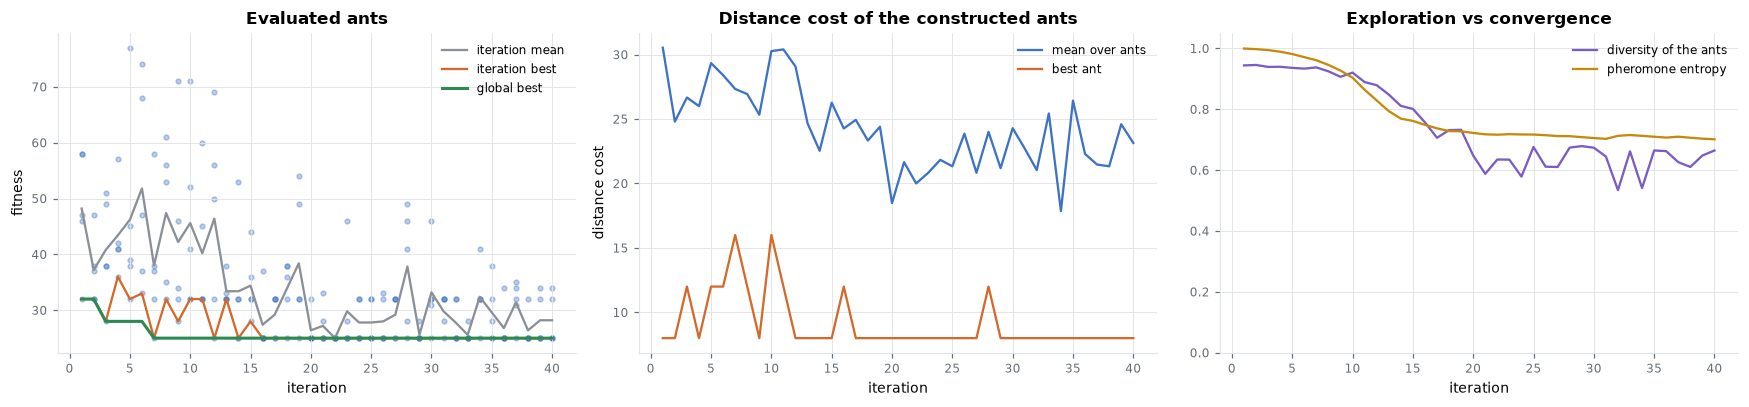

In [9]:
def plot_colony_progress(result):
    """Trois graphiques de suivi : fourmis évaluées, coût de distance des fourmis, diversité et entropie."""
    frame = iterations_frame(result)
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    ax = axes[0]
    # Un point par fourmi évaluée, à l'abscisse de son itération.
    for _, row in frame.iterrows():
        ax.scatter([row["iteration"]] * len(row["costs"]), row["costs"], s=10, color=PHYSICAL, alpha=0.35)
    ax.plot(frame["iteration"], frame["iteration_mean"], color=PALETTE[5], label="iteration mean")
    ax.plot(frame["iteration"], frame["iteration_best"], color=LOGICAL, label="iteration best")
    ax.plot(frame["iteration"], frame["global_best"], color=DISTANCE_COLORS[1], linewidth=2, label="global best")
    ax.set_xlabel("iteration")
    ax.set_ylabel("fitness")
    ax.set_title("Evaluated ants")
    ax.legend()
    axes[1].plot(frame["iteration"], frame["surrogate_mean"], color=PALETTE[0], label="mean over ants")
    axes[1].plot(frame["iteration"], frame["surrogate_min"], color=PALETTE[1], label="best ant")
    axes[1].set_xlabel("iteration")
    axes[1].set_ylabel("distance cost")
    axes[1].set_title("Distance cost of the constructed ants")
    axes[1].legend()
    axes[2].plot(frame["iteration"], frame["diversity"], color=PALETTE[4], label="diversity of the ants")
    axes[2].plot(frame["iteration"], frame["entropy"], color=PALETTE[6], label="pheromone entropy")
    axes[2].set_ylim(0, 1.05)
    axes[2].set_xlabel("iteration")
    axes[2].set_title("Exploration vs convergence")
    axes[2].legend()
    fig.tight_layout()
    return fig


plot_colony_progress(single);

**Évolution des phéromones.** Chaque panneau représente la matrice $\pi_{iu}$ (phéromones normalisées par ligne), la probabilité « mémoire » de placer $q_i$ sur $P_u$. Les carrés bleus marquent $s^{\mathrm{bs}}$ final. On part d'une matrice uniforme ($\pi = 1/m$) ; chaque ligne se concentre ensuite sur quelques colonnes, au plus $\tau_{\max} / (\tau_{\max} + (m-1)\,\tau_{\min})$.

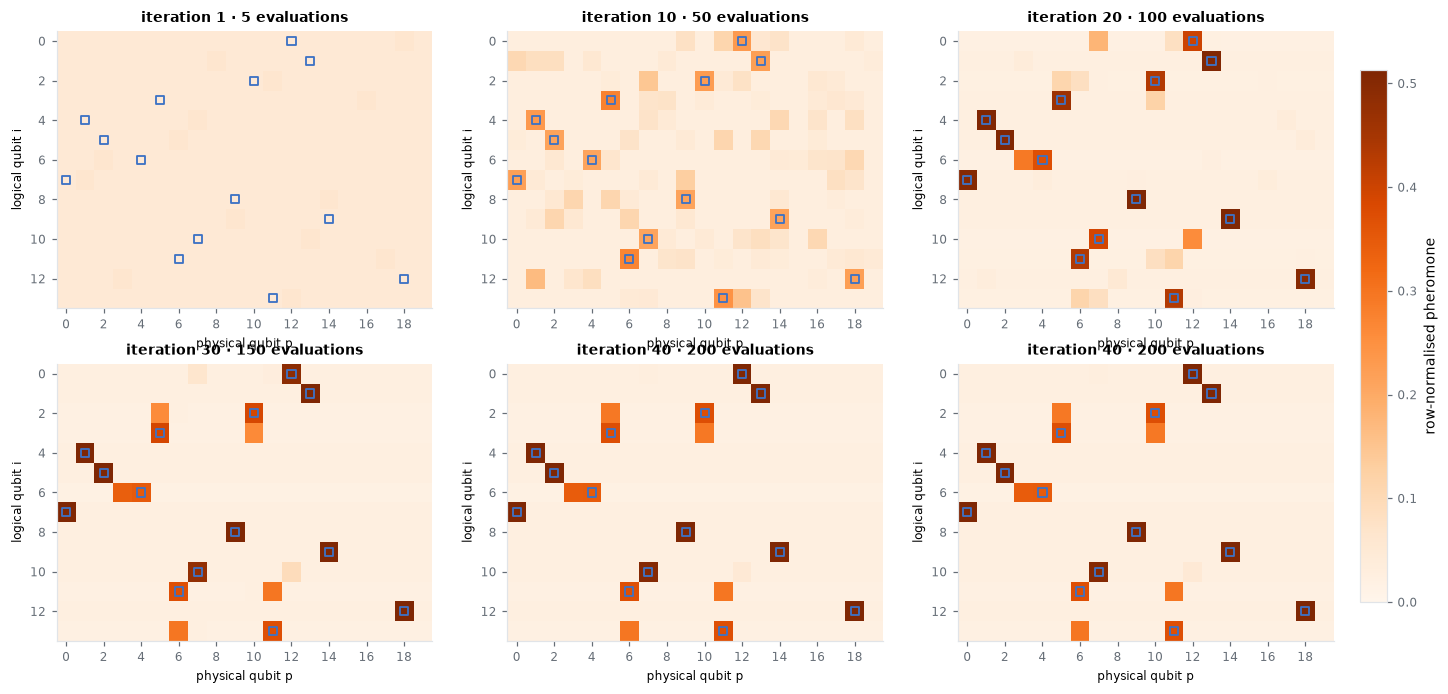

In [10]:
def plot_pheromone_snapshots(result, panels=6):
    """Matrices de phéromones à plusieurs moments de l'exécution, normalisées par ligne, avec le meilleur placement final."""
    snapshots = result.trace["snapshots"]
    # Jusqu'à panels − 1 copies réparties régulièrement, plus l'état final.
    chosen = [snapshots[int(k)] for k in np.unique(np.linspace(0, len(snapshots) - 1, min(panels - 1, len(snapshots))).astype(int))]
    chosen.append({"iteration": len(result.trace["iterations"]), "evaluations": result.evaluations, "pheromone": result.trace["pheromone"]})
    # Normalisation par ligne : chaque ligne devient une distribution de probabilités.
    matrices = [np.array(s["pheromone"]) / np.array(s["pheromone"]).sum(axis=1, keepdims=True) for s in chosen]
    # Même échelle de couleurs pour tous les panneaux.
    top = max(m.max() for m in matrices)
    best = result.trace["best_mapping"]
    fig, axes = subplot_grid(len(chosen), cols=3, width=5.2, height=3.6)
    for ax, snapshot, matrix in zip(axes, chosen, matrices):
        image = ax.imshow(matrix, cmap="Oranges", vmin=0, vmax=top, aspect="auto")
        # Carrés bleus : case (i, meilleur placement de i).
        ax.scatter(best, range(len(best)), marker="s", s=28, facecolors="none", edgecolors=PHYSICAL, linewidths=1.2)
        ax.set_title(f"iteration {snapshot['iteration']} · {snapshot['evaluations']} evaluations", fontsize=9)
        ax.set_xlabel("physical qubit p", fontsize=8)
        ax.set_ylabel("logical qubit i", fontsize=8)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(False)
    fig.colorbar(image, ax=list(axes), fraction=0.02, pad=0.02, label="row-normalised pheromone")
    return fig


plot_pheromone_snapshots(single);

**Ce que la colonie a appris.** Le placement « consensus » se lit dans $\tau$ final : on parcourt les cases $(i, u)$ par phéromone décroissante et on affecte $i \mapsto u$ si $i$ et $u$ sont encore libres.

On le compare à $s^{\mathrm{bs}}$ et à l'identité, chacun réévalué `REEVALUATIONS` fois. Si la moyenne de réévaluation de $s^{\mathrm{bs}}$ est nettement au-dessus de $f(s^{\mathrm{bs}})$, son coût était un tirage chanceux du bruit.

In [11]:
# Réévaluation de trois placements pour les comparer hors du bruit d'une seule évaluation.
# Placement « consensus » lu dans la matrice finale des phéromones.
learned = ant_colony.pheromone_mapping(single.trace["pheromone"])
checker = Problem(instance)
candidates = {"best mapping found": single.best_mapping, "pheromone mapping": learned, "identity": list(range(instance.n))}
rows = []
for label, mapping in candidates.items():
    costs = checker.fitness_samples(mapping, REEVALUATIONS)
    rows.append({"mapping": label, "distance cost": distance_cost(instance, mapping), "min": min(costs), "mean": round(float(np.mean(costs)), 2), "max": max(costs), "std": round(float(np.std(costs)), 2)})
check_table = pd.DataFrame(rows).set_index("mapping")
check_table

,distance cost,min,mean,max,std
mapping,,,,,
best mapping found,16,25,25.0,25,0.0
pheromone mapping,16,25,25.0,25,0.0
identity,56,83,95.0,98,6.0


## 3. Effet des paramètres

Un seul paramètre varie autour de `BASE`, sur deux instances de profils opposés (notebook 02) :
- **instance 3** (QFT) : $\rho_S(C, f) = 0{,}27$, $C$ guide mal ;
- **instance 9** (GHZ en chaîne) : $\rho_S = 0{,}74$, $C$ guide bien.

Le protocole est 3 graines × 200 évaluations par réglage. Le tableau donne `moyenne ± écart-type (meilleur)` de $b_B$ ; la figure donne la convergence moyenne $b_t$.

**Résolution.** Le réglage `BASE` apparaît dans les quatre études (β = 2, ρ = 0,2, 30/5, ls = 0) avec les mêmes graines. Sa moyenne varie de 122 à 133 sur l'instance 3 et de 52 à 56 sur l'instance 9, à cause du bruit de $f$ et de l'exécution en parallèle. Un écart inférieur à ces amplitudes n'est donc pas une différence réelle.

In [12]:
def plot_study(results, title):
    """Convergence moyenne b_t (moyenne sur les graines) de chaque réglage, une colonne par instance."""
    order = list(dict.fromkeys(r.algorithm for r in results))
    instance_ids = sorted({r.instance_id for r in results})
    fig, axes = plt.subplots(1, len(instance_ids), figsize=(5.4 * len(instance_ids), 3.3), squeeze=False)
    for ax, instance_id in zip(axes[0], instance_ids):
        history = history_frame([r for r in results if r.instance_id == instance_id])
        for color, algorithm in zip(PALETTE, order):
            curves = history[history["algorithm"] == algorithm].pivot_table(index="evaluation", columns="seed", values="best").ffill()
            ax.plot(curves.index, curves.mean(axis=1), color=color, label=algorithm, linewidth=1.5)
        ax.set_title(f"Instance {instance_id}")
        ax.set_xlabel("evaluations t", fontsize=8)
        ax.set_ylabel("mean best fitness b_t", fontsize=8)
        ax.legend()
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    return fig


def study(name, values, build):
    """Lance une étude : un réglage par valeur, obtenu en modifiant BASE avec build(valeur)."""
    algorithms = {label: (ant_colony.run, {**BASE, **NO_SNAPSHOTS, **build(value)}) for label, value in values.items()}
    return cached_grid(f"study_{name}", algorithms, STUDY_INSTANCES, STUDY_SEEDS, BUDGET)

### 3.1 Poids de l'heuristique β

Entre un voisin ($g = 0$) et un candidat de coût ajouté $g$, le rapport des probabilités vaut $(1 + g)^\beta$, à phéromones égales.
- $\beta = 0$ : construction uniforme ; seule $\tau$ apprend, et 40 itérations ne suffisent pas.
- $\beta \to \infty$ : glouton sur $C$.

On attend un grand $\beta$ favorable là où $C$ est fiable (instance 9), et défavorable là où il ne l'est pas (instance 3).

Loaded 24 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\study_beta.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
beta=0,135.3 ± 4.8 (131),95.3 ± 6.5 (87)
beta=1,132.0 ± 2.4 (129),70.3 ± 1.9 (69)
beta=2,130.3 ± 5.7 (123),56.3 ± 7.1 (49)
beta=4,136.7 ± 7.6 (126),53.0 ± 0.8 (52)


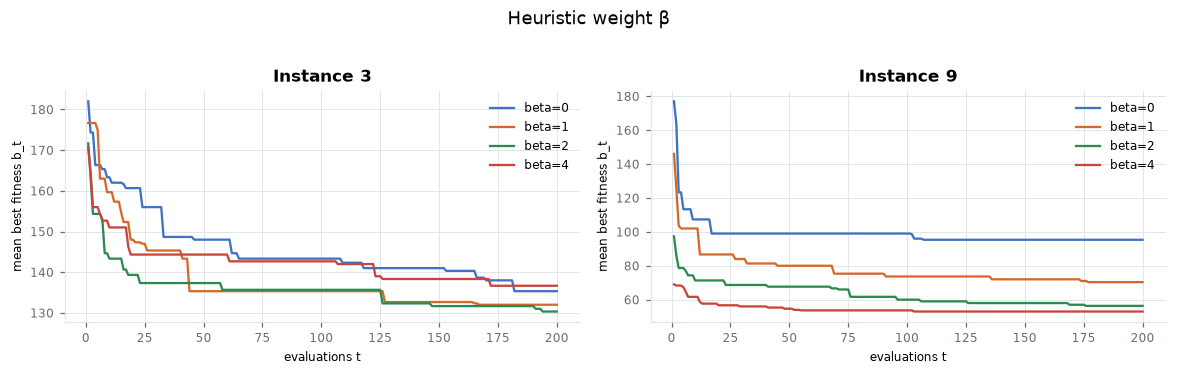

In [13]:
beta_study = study("beta", {"beta=0": 0.0, "beta=1": 1.0, "beta=2": 2.0, "beta=4": 4.0}, lambda v: {"beta": v})
beta_table = display_table(results_frame(beta_study))
display(beta_table)
plot_study(beta_study, "Heuristic weight β");

### 3.2 Évaporation ρ

Demi-vie d'un dépôt :

$$
h_{1/2} = \frac{\ln 2}{-\ln(1-\rho)}
$$

Elle vaut 13,5 ; 6,6 ; 3,1 et 1,4 itérations pour $\rho$ = 0,05 ; 0,1 ; 0,2 et 0,4, à comparer aux $T = 40$ itérations disponibles.
- $\rho$ petit : la mémoire couvre une grande partie de l'exécution, et l'apprentissage est lent.
- $\rho$ grand : la colonie ne retient que les dernières itérations, donc suit les derniers tirages, y compris le bruit.

Le rapport $\tau_{\max} / \tau_{\min} = 1/r$ ne dépend pas de $\rho$.

Loaded 24 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\study_rho.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
rho=0.05,132.3 ± 5.9 (124),64.0 ± 1.4 (63)
rho=0.1,125.7 ± 4.5 (122),58.0 ± 4.5 (53)
rho=0.2,122.3 ± 5.0 (117),52.0 ± 3.7 (48)
rho=0.4,132.3 ± 4.0 (129),62.0 ± 7.1 (56)


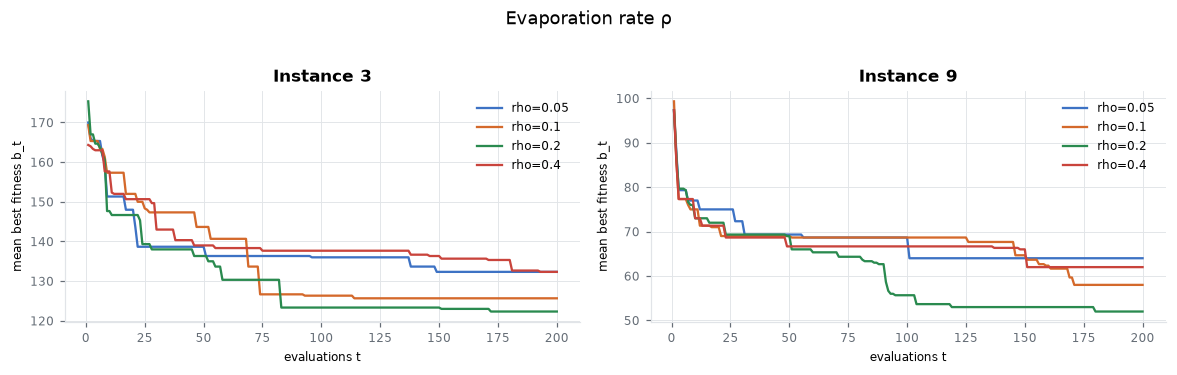

In [14]:
rho_study = study("rho", {"rho=0.05": 0.05, "rho=0.1": 0.1, "rho=0.2": 0.2, "rho=0.4": 0.4}, lambda v: {"rho": v})
rho_table = display_table(results_frame(rho_study))
display(rho_table)
plot_study(rho_study, "Evaporation rate ρ");

### 3.3 Taille de la colonie et filtrage par $C$

Le réglage noté $N / N_e$ donne $T = B / N_e$ itérations : 20 pour `10/10`, 10 pour `20/20`, 40 pour `30/5` et `60/5`.
- **Sans filtre** ($N_e = N$), chaque fourmi coûte une évaluation.
- **Avec filtre**, on garde la fraction $N_e / N$ des fourmis de plus petit $C$ (1/6 pour `30/5`, 1/12 pour `60/5`). C'est une sélection gratuite par $C$, utile dans la mesure où $\rho_S(C, f)$ est élevé.

Loaded 24 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\study_colony.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
10/10,131.3 ± 4.5 (126),72.3 ± 4.5 (66)
20/20,139.0 ± 5.0 (135),68.0 ± 8.3 (57)
30/5,129.3 ± 7.1 (122),55.0 ± 2.9 (52)
60/5,124.0 ± 0.8 (123),53.3 ± 2.6 (51)


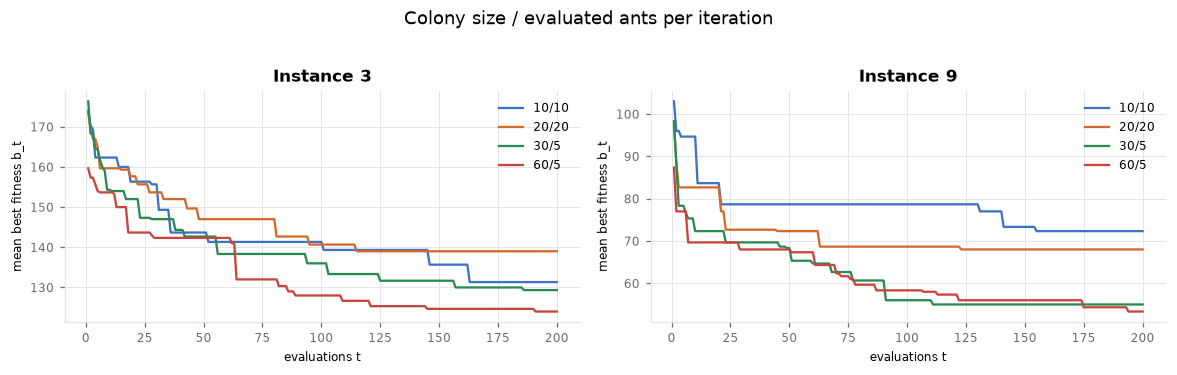

In [15]:
colony_study = study("colony", {"10/10": (10, 10), "20/20": (20, 20), "30/5": (30, 5), "60/5": (60, 5)}, lambda v: {"ants": v[0], "evaluated": v[1]})
colony_table = display_table(results_frame(colony_study))
display(colony_table)
plot_study(colony_study, "Colony size / evaluated ants per iteration");

### 3.4 Recherche locale sur $C$

Chaque fourmi subit $K$ essais de transposition acceptés si $\Delta C \le 0$ (`surrogate_descent`), avant le tri. Les fourmis sont ainsi poussées vers des minima locaux **de $C$**. On attend un effet positif seulement si $C$ classe bien les placements (instance 9).

Remarque : combiner les fourmis et une recherche locale relève de l'hybridation. Cette variante est conservée ici comme étude.

Loaded 24 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\study_local_search.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
ls=0,133.3 ± 6.0 (125),52.7 ± 2.6 (49)
ls=50,134.3 ± 4.8 (130),50.7 ± 1.2 (49)
ls=200,135.3 ± 7.5 (130),53.7 ± 3.7 (49)
ls=1000,136.3 ± 1.2 (135),49.7 ± 3.3 (45)


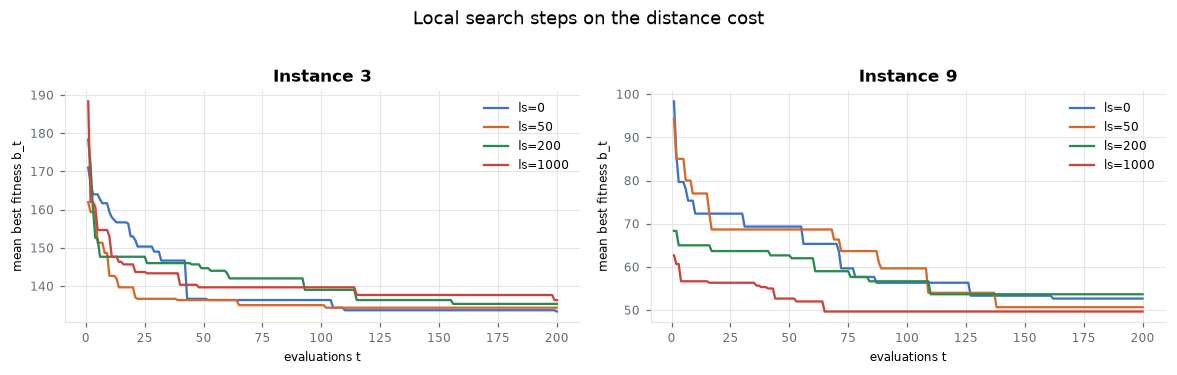

In [16]:
local_study = study("local_search", {"ls=0": 0, "ls=50": 50, "ls=200": 200, "ls=1000": 1000}, lambda v: {"local_search_steps": v})
local_table = display_table(results_frame(local_study))
display(local_table)
plot_study(local_study, "Local search steps on the distance cost");

## 4. Comparaison avec les références (9 instances, 5 graines, $B = 200$)

| Variante | $N$ | $N_e$ | $T$ | Particularité |
|---|---|---|---|---|
| `aco_all` | 10 | 10 | 20 | toutes les fourmis sont évaluées |
| `aco_filtered` | 30 | 5 | 40 | réglage `BASE` |
| `aco_filtered_ls` | 30 | 5 | 40 | plus 200 essais de descente sur $C$ par fourmi |

Références : `identity` (minimum de $B$ tirages du bruit autour de $F(\mathrm{id})$), `random_search` (placements uniformes) et `surrogate_filtered` (meilleur de 200 placements aléatoires selon $C$, sans mémoire ; voir notebook 03).

La comparaison avec les autres métaheuristiques (gains, profil de performance, convergence) est dans le notebook 99.

In [17]:
# Les six algorithmes comparés, avec leurs paramètres.
COMPARISON = {
    "identity": (identity.run, {}),
    "random_search": (random_search.run, {}),
    "surrogate_filtered": (surrogate_filtered.run, {"candidates": 200}),
    "aco_all": (ant_colony.run, {**BASE, **NO_SNAPSHOTS, "ants": 10, "evaluated": 10}),
    "aco_filtered": (ant_colony.run, {**BASE, **NO_SNAPSHOTS}),
    "aco_filtered_ls": (ant_colony.run, {**BASE, **NO_SNAPSHOTS, "local_search_steps": 200}),
}
comparison = cached_grid("comparison", COMPARISON, COMPARISON_INSTANCES, SEEDS, BUDGET)
# Une ligne par exécution.
frame = results_frame(comparison)
# Ordre d'affichage des algorithmes.
ORDER = list(COMPARISON)

Loaded 270 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\comparison.jsonl


`moyenne ± écart-type (meilleur)` de $b_B$ sur les graines :

In [18]:
summary_table = display_table(frame).reindex(ORDER)
summary_table

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9
algorithm,,,,,,,,,
identity,57.0 ± 0.0 (57),59.0 ± 0.0 (59),141.0 ± 0.0 (141),62.0 ± 0.0 (62),332.2 ± 1.0 (331),78.2 ± 2.4 (77),107.0 ± 0.0 (107),66.8 ± 1.0 (66),137.0 ± 0.0 (137)
random_search,38.4 ± 2.1 (36),90.2 ± 4.5 (86),139.4 ± 5.2 (132),42.4 ± 0.8 (42),334.0 ± 9.0 (323),39.6 ± 3.7 (35),73.6 ± 7.2 (63),40.0 ± 3.8 (34),98.2 ± 3.5 (93)
surrogate_filtered,34.8 ± 1.7 (33),75.8 ± 2.9 (71),140.0 ± 2.2 (137),38.8 ± 1.5 (36),332.0 ± 4.9 (326),33.8 ± 2.1 (31),64.6 ± 6.3 (57),38.4 ± 2.4 (34),90.2 ± 10.4 (79)
aco_all,28.6 ± 2.9 (25),59.0 ± 0.0 (59),131.0 ± 3.7 (124),36.2 ± 1.0 (35),324.8 ± 2.9 (320),25.6 ± 1.2 (25),39.8 ± 5.9 (34),25.8 ± 3.9 (22),69.8 ± 6.4 (59)
aco_filtered,30.0 ± 0.9 (29),59.0 ± 0.0 (59),128.0 ± 5.2 (122),33.8 ± 2.4 (30),323.0 ± 4.4 (317),25.0 ± 0.0 (25),25.2 ± 2.9 (22),21.6 ± 2.0 (19),54.4 ± 2.8 (51)
aco_filtered_ls,33.4 ± 1.5 (32),59.0 ± 0.0 (59),132.4 ± 2.5 (130),38.6 ± 2.6 (35),328.6 ± 0.5 (328),26.2 ± 1.5 (25),22.6 ± 1.2 (22),19.2 ± 1.9 (17),53.8 ± 2.4 (51)


Rang de la moyenne de $b_B$ sur chaque instance (1 = meilleure), puis rang moyen :

In [19]:
# Moyenne du meilleur coût par algorithme (lignes) et instance (colonnes).
means = frame.groupby(["algorithm", "instance_id"])["best_cost"].mean().unstack()
# Rang dans chaque colonne (1 = plus petite moyenne ; égalités = même rang).
ranks = means.rank(axis=0, method="min").rename(columns=lambda c: f"inst. {c}")
ranks["mean rank"] = ranks.mean(axis=1).round(2)
ranks = ranks.sort_values("mean rank")
ranks

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9,mean rank
algorithm,,,,,,,,,,
aco_filtered,2.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.44
aco_all,1.0,1.0,2.0,2.0,2.0,2.0,3.0,3.0,3.0,2.11
aco_filtered_ls,3.0,1.0,3.0,3.0,3.0,3.0,1.0,1.0,1.0,2.11
surrogate_filtered,4.0,5.0,5.0,4.0,4.0,4.0,4.0,4.0,4.0,4.22
random_search,5.0,6.0,4.0,5.0,6.0,5.0,5.0,5.0,5.0,5.11
identity,6.0,1.0,6.0,6.0,5.0,6.0,6.0,6.0,6.0,5.33


**Significativité : test de Mann-Whitney unilatéral.** Il compare les échantillons $X$ (`aco_filtered`) et $Y$ (autre algorithme), de 5 graines chacun :

$$
U = \sum_{x \in X} \sum_{y \in Y} \Big( \mathbf{1}[x < y] + \tfrac12\,\mathbf{1}[x = y] \Big), \qquad H_0 : \mathbb{P}(X < Y) = \tfrac12, \qquad H_1 : \mathbb{P}(X < Y) > \tfrac12
$$

La *p-value* est la probabilité, sous $H_0$, d'un $U$ au moins aussi grand. On conclut à un avantage si $p < 0{,}05$. Avec $5 + 5$ valeurs, le plus petit $p$ possible est $1/\binom{10}{5} \approx 0{,}004$ : un $p$ élevé ne prouve pas l'égalité.

In [20]:
def significance(frame, algorithm, others):
    """p-values du test de Mann-Whitney « algorithm est meilleur que other », par instance (lignes) et adversaire (colonnes)."""
    rows = {}
    for instance_id in sorted(frame["instance_id"].unique()):
        subset = frame[frame["instance_id"] == instance_id]
        target = subset.loc[subset["algorithm"] == algorithm, "best_cost"]
        rows[f"inst. {instance_id}"] = {
            # alternative="less" : on teste si les coûts de `algorithm` sont plus petits.
            other: stats.mannwhitneyu(target, subset.loc[subset["algorithm"] == other, "best_cost"], alternative="less").pvalue
            for other in others
        }
    return pd.DataFrame(rows).T.round(4)


p_values = significance(frame, "aco_filtered", ["identity", "random_search", "surrogate_filtered", "aco_all"])
p_values

,identity,random_search,surrogate_filtered,aco_all
inst. 1,0.0035,0.0058,0.0057,0.5888
inst. 2,1.0000,0.0036,0.0037,1.0000
inst. 3,0.0037,0.0139,0.0078,0.1729
inst. 4,0.0036,0.0047,0.0096,0.0663
inst. 5,0.0055,0.0694,0.0181,0.2979
inst. 6,0.0028,0.0036,0.0037,0.2119
inst. 7,0.0036,0.0060,0.0058,0.0058
inst. 8,0.0053,0.0060,0.0060,0.0289
inst. 9,0.0035,0.0058,0.0058,0.0058


## 5. Meilleures solutions

Pour chaque instance, on prend le meilleur $s^{\mathrm{bs}}$ des variantes ACO et on le réévalue `REEVALUATIONS` fois pour estimer $F(s^{\mathrm{bs}})$. Le fichier `GROUP_Challenge_N.txt` est écrit avec le meilleur coût observé, **seulement s'il bat** la solution déjà présente dans `solutions/`.

In [21]:
rows = []
for instance_id in COMPARISON_INSTANCES:
    # Toutes les exécutions ACO sur cette instance, et la meilleure d'entre elles.
    runs = [r for r in comparison if r.instance_id == instance_id and r.algorithm.startswith("aco")]
    best = min(runs, key=lambda r: r.best_cost)
    # Réévaluations du meilleur placement.
    checks = Problem(load_instance(instance_id)).fitness_samples(best.best_mapping, REEVALUATIONS)
    # Meilleur coût observé pour ce placement (pendant la recherche ou pendant les réévaluations).
    cost = min(best.best_cost, min(checks))
    path, written, previous = write_solution_if_better(best.best_mapping, cost, instance_id, group=GROUP, directory=SOLUTIONS_DIR)
    identity_mean = frame[(frame["instance_id"] == instance_id) & (frame["algorithm"] == "identity")]["best_cost"].mean()
    rows.append({
        "instance": instance_id,
        "algorithm": best.algorithm,
        "seed": best.seed,
        "cost during search": best.best_cost,
        "re-evaluation min": min(checks),
        "re-evaluation mean": round(float(np.mean(checks)), 2),
        "re-evaluation std": round(float(np.std(checks)), 2),
        "identity (best of budget)": round(float(identity_mean), 1),
        "file": path.name,
        "file status": "written" if written else f"kept (existing cost {previous:g})",
        # Placement en texte pour un affichage lisible.
        "mapping": " ".join(map(str, best.best_mapping)),
    })
best_solutions = pd.DataFrame(rows).set_index("instance")
best_solutions

,algorithm,seed,cost during search,re-evaluation min,re-evaluation mean,re-evaluation std,identity (best of budget),file,file status,mapping
instance,,,,,,,,,,
1,aco_all,2,25,25,26.4,2.80,57.0,Groupe0_Challenge_1.txt,kept (existing cost 25),0 14 13 2 12 3 11 15 4 10 5 1
2,aco_all,0,59,59,59.0,0.00,59.0,Groupe0_Challenge_2.txt,kept (existing cost 59),10 11 12 13 14 15 0 1 2 3 4 5 6 7 8 9
3,aco_filtered,0,122,135,142.2,4.53,141.0,Groupe0_Challenge_3.txt,kept (existing cost 122),6 9 10 7 12 3 4 11 8 5
4,aco_filtered,3,30,30,31.2,1.47,62.0,Groupe0_Challenge_4.txt,kept (existing cost 30),7 8 12 6 1 16 14 4 13 2 10 18 11 3 0 19 9 5 17
5,aco_filtered,1,317,317,330.1,8.58,332.2,Groupe0_Challenge_5.txt,kept (existing cost 316),5 6 8 7 16 17 11 14 10 12 13 18
6,aco_all,0,25,25,25.0,0.00,78.2,Groupe0_Challenge_6.txt,kept (existing cost 25),1 13 8 3 11 10 5 16 9 14 6 2 18 7
7,aco_filtered,0,22,22,22.0,0.00,107.0,Groupe0_Challenge_7.txt,kept (existing cost 22),9 8 5 3 2 1 4 7 12 10 13 14 16 19 22 24 25 23 ...
8,aco_filtered_ls,0,17,17,18.5,2.29,66.8,Groupe0_Challenge_8.txt,kept (existing cost 17),14 13 23 24 10 12 3 5 19 22 25 8 21 15 18 2 16...
9,aco_filtered,0,51,54,55.2,1.47,137.0,Groupe0_Challenge_9.txt,kept (existing cost 51),6 13 18 21 23 24 25 26 22 19 16 14 11 8 5 3 2 ...


## Conclusions

_Comparaison du 12/11/2026 : $B = 200$, 5 graines, 9 instances. Les chiffres bougent un peu d'une exécution à l'autre (bruit de $f$), les tendances non._

### Résultat principal

`aco_filtered` a le meilleur rang moyen (1,44). Elle est significativement meilleure ($p < 0{,}05$) que `surrogate_filtered` sur les 9 instances, et que `random_search` sur 8 instances sur 9 (instance 5 : $p \approx 0{,}07$).

| Instance | 7 | 6 | 8 | 9 | 1 | 4 | 3 | 5 | 2 |
|---|---|---|---|---|---|---|---|---|---|
| identité | 107,0 | 78,2 | 66,8 | 137,0 | 57,0 | 62,0 | 141,0 | 332,2 | 59,0 |
| `aco_filtered` | 25,2 | 25,0 | 21,6 | 54,4 | 30,0 | 33,8 | 128,0 | 323,0 | 59,0 |
| gain | −76 % | −68 % | −68 % | −60 % | −47 % | −45 % | −9 % | −3 % | 0 % |

**Interprétation.** Les gains suivent $\rho_S(C, f)$ (notebook 02) :
- **Instances où $C$ est fiable** (6 à 9) : gains de 60 à 76 %. L'heuristique $\eta$ et le filtrage par $C$ y vont dans le bon sens.
- **Instances 3 et 5** ($\rho_S \le 0{,}33$) : gains de 3 à 9 %. $\eta$ et le filtrage poussent vers de petits $C$ qui ne sont pas de petits $f$, et 40 itérations ne suffisent pas à $\tau$ pour corriger ce biais.
- **Instance 2** : l'identité suit déjà la chaîne de la puce ($C(\mathrm{id}) = 0$) ; 59 est vraisemblablement l'optimum.

### Paramètres (instances 3 et 9 ; résolution de l'étude : environ ±5 sur 3, environ ±2 sur 9)

- **β.** Sur l'instance 9, on passe de 95,3 (β = 0) à 53,0 (β = 4) : sans heuristique, $\tau$ seule n'apprend pas en 40 itérations. Sur l'instance 3, β = 4 est en tendance le pire réglage (136,7) : un glouton sur un $C$ mal corrélé égare la colonie. β = 2 est le compromis.
- **ρ.** ρ = 0,2 ($h_{1/2} \approx 3$ itérations) est le meilleur sur les deux instances (122,3 et 52,0). Avec ρ = 0,05 ($h_{1/2} \approx 13$), la mémoire est trop longue pour 40 itérations ; avec ρ = 0,4 ($h_{1/2} \approx 1{,}4$), la colonie suit les derniers tirages bruités.
- **Filtrage par $C$.** C'est le gain principal. Sur l'instance 9, `30/5` et `60/5` (40 itérations) donnent environ 54, contre environ 70 pour `10/10` et `20/20` (20 et 10 itérations). Dans la comparaison, `aco_filtered` bat `aco_all` significativement sur 7, 8 et 9.
- **Recherche locale sur $C$.** Les écarts restent dans la résolution de l'étude sur les deux instances. Sur les 9 instances, `aco_filtered_ls` est 1re sur 7, 8 et 9 ($\rho_S \ge 0{,}74$) mais 3e sur 1, 3, 4 et 5 : elle n'aide que là où $C$ est fiable.

### Limites

- **Malédiction du vainqueur.** $b_B$ est le minimum de 200 évaluations bruitées. Sur l'instance 3, le meilleur placement vaut 122 pendant la recherche mais environ 141 en moyenne à la réévaluation (section 5). Sur 2, 6, 7, 8 et 9, la solution est stable.
- **Temps.** Une exécution prend de 20 s à 2,5 min, presque entièrement dans `fitness_inner`.

### Pistes

1. **Choisir la solution rendue par réévaluation** : prendre la meilleure moyenne sur $k$ évaluations plutôt que le minimum d'une seule.
2. **Instances 3 et 5** : moins de poids à $C$ ($\beta$ plus petit, filtre moins sélectif, par exemple $N_e / N = 15/30$).
3. **Plus de budget** là où $b_t$ descend encore à $t = 200$ (instances 1, 3, 4, 7, 8).